In [1]:


# Sector ETF proxies
sector_etfs = {
    "IT": "ITBEES.NS",
    "Banks": "BANKBEES.NS",
    "Autos": "AUTOBEES.NS",
    "Healthcare": "HEALTHIETF.NS",
}

tickers = list(dict.fromkeys(stock_tickers + list(sector_etfs.values())))

# auto_adjust=True uses dividend- and split-adjusted prices
data = yf.download(
    tickers=tickers,
    period="5y",       # Change to e.g. "1y", "2y", or use start= and end=
    interval="1d",
    auto_adjust=True,
    group_by="column",
    progress=False,
    threads=True,
)

if data.empty or "Close" not in data.columns:
    raise RuntimeError("Yahoo Finance returned no closing-price data.")

prices = data["Close"].sort_index()

# Fail explicitly rather than silently continuing with missing tickers
missing = prices.columns[prices.isna().all()].tolist()
if missing:
    raise RuntimeError(f"No Yahoo Finance data returned for: {missing}")

# Simple daily returns: (today's adjusted close / yesterday's adjusted close) - 1
returns = prices.pct_change(fill_method=None).dropna(how="all")

prices.to_csv("nifty50_and_sector_etf_prices.csv")
returns.to_csv("nifty50_and_sector_etf_returns.csv")

display(returns.tail())

: 

: 

In [ ]:
import pandas as pd
import yfinance as yf

# Get the current NIFTY 50 constituents
constituents_url = (
    "https://www.niftyindices.com/IndexConstituent/ind_nifty50list.csv"
)
constituents = pd.read_csv(constituents_url)

if "Symbol" not in constituents.columns:
    raise ValueError(
        f"Expected a 'Symbol' column in the constituents file; "
        f"found: {constituents.columns.tolist()}"
    )

stock_tickers = (
    constituents["Symbol"].dropna().astype(str).str.strip().add(".NS").tolist()
)
stock_tickers

In [1]:
import pandas as pd
import yfinance as yf

# Yahoo Finance symbols for NIFTY 50 stocks (NSE suffix: .NS)
nifty50 = [
    "ADANIENT.NS", "ADANIPORTS.NS", "APOLLOHOSP.NS", "ASIANPAINT.NS",
    "AXISBANK.NS", "BAJAJ-AUTO.NS", "BAJFINANCE.NS", "BAJAJFINSV.NS",
    "BEL.NS", "BPCL.NS", "BHARTIARTL.NS", "CIPLA.NS", "COALINDIA.NS",
    "DRREDDY.NS", "EICHERMOT.NS", "GRASIM.NS", "HCLTECH.NS",
    "HDFCBANK.NS", "HDFCLIFE.NS", "HEROMOTOCO.NS", "HINDALCO.NS",
    "HINDUNILVR.NS", "ICICIBANK.NS", "ITC.NS", "INDUSINDBK.NS",
    "INFY.NS", "JSWSTEEL.NS", "KOTAKBANK.NS", "LT.NS", "M&M.NS",
    "MARUTI.NS", "NESTLEIND.NS", "NTPC.NS", "ONGC.NS", "POWERGRID.NS",
    "RELIANCE.NS", "SBILIFE.NS", "SBIN.NS", "SUNPHARMA.NS", "TCS.NS",
    "TATACONSUM.NS", "TATAMOTORS.NS", "TATASTEEL.NS", "TECHM.NS",
    "TITAN.NS", "TRENT.NS", "ULTRACEMCO.NS", "WIPRO.NS",
    "SHRIRAMFIN.NS", "JIOFIN.NS",
]

# Yahoo Finance symbols for sector ETF proxies
sector_etfs = [
    "ITBEES.NS",       # IT
    "BANKBEES.NS",     # Banks
    "AUTOBEES.NS",     # Autos
    "HEALTHIETF.NS",   # Healthcare
    # "PHARMABEES.NS", # Pharma alternative
]

tickers = nifty50 + sector_etfs

# Yahoo Finance query: 5 years of daily, adjusted prices
data = yf.download(
    tickers=tickers,
    period="5y",
    interval="1d",
    auto_adjust=True,
    group_by="column",
    progress=False,
    threads=True,
)

if data.empty:
    raise RuntimeError("Yahoo Finance returned no data. Check your internet connection.")

# Extract adjusted close prices across yfinance column layouts
if isinstance(data.columns, pd.MultiIndex):
    close_level = next(
        (
            level
            for level in range(data.columns.nlevels)
            if "Close" in data.columns.get_level_values(level)
        ),
        None,
    )
    if close_level is None:
        raise RuntimeError(f"No Close prices found. Columns: {data.columns}")
    prices = data.xs("Close", axis=1, level=close_level)
else:
    prices = data[["Close"]].rename(columns={"Close": tickers[0]})

# Report symbols for which Yahoo returned no prices
missing = [ticker for ticker in tickers if ticker not in prices.columns
           or prices[ticker].isna().all()]
if missing:
    print("No price data returned for:", missing)

prices = prices.dropna(axis=1, how="all")
returns = prices.pct_change(fill_method=None).dropna(how="all")

prices.to_csv("nifty50_sector_etf_prices.csv")
returns.to_csv("nifty50_sector_etf_returns.csv")

print("Prices:", prices.shape)
print("Returns:", returns.shape)
display(returns.tail())

HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: TATAMOTORS.NS"}}}
$TATAMOTORS.NS: possibly delisted; no price data found  (period=5y) (Yahoo error = "No data found, symbol may be delisted")

1 Failed download:
['TATAMOTORS.NS']: possibly delisted; no price data found  (period=5y) (Yahoo error = "No data found, symbol may be delisted")


No price data returned for: ['TATAMOTORS.NS']
Prices: (1236, 53)
Returns: (1235, 53)


Ticker,ADANIENT.NS,ADANIPORTS.NS,APOLLOHOSP.NS,ASIANPAINT.NS,AUTOBEES.NS,AXISBANK.NS,BAJAJ-AUTO.NS,BAJAJFINSV.NS,BAJFINANCE.NS,BANKBEES.NS,...,SHRIRAMFIN.NS,SUNPHARMA.NS,TATACONSUM.NS,TATASTEEL.NS,TCS.NS,TECHM.NS,TITAN.NS,TRENT.NS,ULTRACEMCO.NS,WIPRO.NS
Date,,,,,,,,,,,,,,,,,,,,,
2026-10-05,0.016757,0.020831,-0.018258,-0.017034,-0.003148,0.004190,-0.002091,0.010851,0.022883,0.001026,...,0.027937,-0.011827,-0.003396,0.000787,0.018988,0.001892,0.014239,0.000000,0.013072,0.017509
2026-10-06,-0.004923,0.005299,-0.008829,0.024598,0.006811,0.021110,-0.000698,0.000571,-0.007113,0.006789,...,-0.006537,0.013710,0.023329,0.003087,-0.006810,-0.020444,-0.006550,0.126357,-0.009217,-0.001850
2026-10-07,-0.037510,-0.018672,0.000316,-0.021492,-0.013983,-0.004407,-0.013277,-0.005193,0.000779,0.001352,...,-0.017667,-0.012804,-0.007684,-0.017069,-0.009381,-0.008907,-0.038022,-0.005403,-0.008558,-0.013841
2026-10-08,-0.053591,-0.024056,-0.031704,-0.025505,NaN,0.002012,-0.024990,-0.020249,-0.008196,NaN,...,-0.032437,-0.011903,-0.017140,-0.020952,-0.002067,0.003420,-0.003998,-0.004844,-0.021768,-0.007644
2026-10-09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import adfuller

# Use the NIFTY 50 list and returns DataFrame from the earlier cell.
stock_returns = returns[[ticker for ticker in nifty50 if ticker in returns.columns]]

if stock_returns.empty:
    raise ValueError("No NIFTY 50 stock columns found in `returns`.")

results = []

for ticker in stock_returns.columns:
    series = pd.to_numeric(stock_returns[ticker], errors="coerce")
    series = series.replace([np.inf, -np.inf], np.nan).dropna()

    try:
        adf_stat, p_value, lags, observations, critical_values, _ = adfuller(
            series,
            regression="c",
            autolag="AIC",
        )
        results.append({
            "Ticker": ticker,
            "Observations": observations,
            "ADF statistic": adf_stat,
            "p-value": p_value,
            "5% critical value": critical_values["5%"],
            "Stationary at 5%": p_value < 0.05,
        })
    except ValueError as exc:
        # Keep the ticker visible in the output if the test cannot run.
        results.append({
            "Ticker": ticker,
            "Observations": len(series),
            "ADF statistic": np.nan,
            "p-value": np.nan,
            "5% critical value": np.nan,
            "Stationary at 5%": f"Test failed: {exc}",
        })

adf_results = pd.DataFrame(results).sort_values(
    "p-value", na_position="last"
)

display(adf_results)

,Ticker,Observations,ADF statistic,p-value,5% critical value,Stationary at 5%
1,ADANIPORTS.NS,1233,-36.416049,0.000000e+00,-2.863887,True
3,ASIANPAINT.NS,1233,-31.976742,0.000000e+00,-2.863887,True
5,BAJAJ-AUTO.NS,1233,-34.784760,0.000000e+00,-2.863887,True
4,AXISBANK.NS,1232,-22.672363,0.000000e+00,-2.863889,True
6,BAJFINANCE.NS,1233,-35.879437,0.000000e+00,-2.863887,True
7,BAJAJFINSV.NS,1233,-33.811067,0.000000e+00,-2.863887,True
9,BPCL.NS,1233,-35.220411,0.000000e+00,-2.863887,True
8,BEL.NS,1233,-35.644389,0.000000e+00,-2.863887,True
14,EICHERMOT.NS,1233,-33.698776,0.000000e+00,-2.863887,True
13,DRREDDY.NS,1233,-33.519570,0.000000e+00,-2.863887,True


In [6]:
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import grangercausalitytests
from IPython.display import display

N_RANDOM_STOCKS = 50
MAX_LAG = 5
SIGNIFICANCE_LEVEL = 0.05
RANDOM_SEED = 42

# Select available NIFTY 50 return columns with enough observations to test.
available = [ticker for ticker in nifty50 if ticker in returns.columns]
eligible = [
    ticker for ticker in available
    if returns[ticker].dropna().shape[0] > 10 * MAX_LAG
]

if len(eligible) < 2:
    raise ValueError(
        "Need at least two NIFTY 50 stocks with sufficient return data."
    )

rng = np.random.default_rng(RANDOM_SEED)
sampled_stocks = rng.choice(
    eligible,
    size=min(N_RANDOM_STOCKS, len(eligible)),
    replace=False,
).tolist()

print("Randomly selected stocks:", sampled_stocks)

# Rows are potential causes; columns are potential effects.
granger_matrix = pd.DataFrame(
    "",
    index=sampled_stocks,
    columns=sampled_stocks,
    dtype=object,
)
pvalue_matrix = pd.DataFrame(
    np.nan,
    index=sampled_stocks,
    columns=sampled_stocks,
)

for source in sampled_stocks:
    for target in sampled_stocks:
        if source == target:
            continue

        pair = returns[[target, source]].replace(
            [np.inf, -np.inf], np.nan
        ).dropna()

        if len(pair) <= 10 * MAX_LAG:
            raise ValueError(
                f"Not enough overlapping observations for {source} -> {target}: "
                f"{len(pair)}"
            )

        # statsmodels expects [target, source] to test whether source
        # Granger-causes target.
        test_results = grangercausalitytests(
            pair[[target, source]],
            maxlag=MAX_LAG,
            verbose=False,
        )

        # Use the SSR F-test at the fixed maximum lag.
        pvalue = test_results[MAX_LAG][0]["ssr_ftest"][1]
        pvalue_matrix.loc[source, target] = pvalue

        if pvalue < SIGNIFICANCE_LEVEL:
            granger_matrix.loc[source, target] = "Yes"

# Green = significant; blank white cells = not significant (or diagonal).
def highlight_yes(row):
    return [
        "background-color: lightgreen" if value == "Yes"
        else "background-color: white"
        for value in row
    ]

display(
    granger_matrix.style
    .apply(highlight_yes, axis=1)
    .set_caption(
        f"Granger causality on daily returns (lag={MAX_LAG}, "
        f"p < {SIGNIFICANCE_LEVEL}) — row → column"
    )
)

Randomly selected stocks: ['BAJAJFINSV.NS', 'ADANIENT.NS', 'EICHERMOT.NS', 'HDFCLIFE.NS', 'BAJAJ-AUTO.NS', 'HEROMOTOCO.NS', 'BPCL.NS', 'KOTAKBANK.NS', 'TRENT.NS', 'ITC.NS', 'TATASTEEL.NS', 'HDFCBANK.NS', 'ULTRACEMCO.NS', 'INDUSINDBK.NS', 'MARUTI.NS', 'TITAN.NS', 'TATACONSUM.NS', 'SBILIFE.NS', 'WIPRO.NS', 'SHRIRAMFIN.NS', 'TCS.NS', 'NESTLEIND.NS', 'GRASIM.NS', 'ASIANPAINT.NS', 'M&M.NS', 'AXISBANK.NS', 'TECHM.NS', 'JIOFIN.NS', 'APOLLOHOSP.NS', 'CIPLA.NS', 'SUNPHARMA.NS', 'BHARTIARTL.NS', 'DRREDDY.NS', 'NTPC.NS', 'COALINDIA.NS', 'JSWSTEEL.NS', 'POWERGRID.NS', 'INFY.NS', 'LT.NS', 'BAJFINANCE.NS', 'ICICIBANK.NS', 'ADANIPORTS.NS', 'HINDUNILVR.NS', 'HINDALCO.NS', 'HCLTECH.NS', 'BEL.NS', 'RELIANCE.NS', 'SBIN.NS', 'ONGC.NS']


C:\Users\p18pr\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\statsmodels\tsa\stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
C:\Users\p18pr\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\statsmodels\tsa\stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
C:\Users\p18pr\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\statsmodels\tsa\stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
C:\Users\p18pr\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\statsmodels\tsa\stattools.py:1556: FutureWarning: verb

,BAJAJFINSV.NS,ADANIENT.NS,EICHERMOT.NS,HDFCLIFE.NS,BAJAJ-AUTO.NS,HEROMOTOCO.NS,BPCL.NS,KOTAKBANK.NS,TRENT.NS,ITC.NS,TATASTEEL.NS,HDFCBANK.NS,ULTRACEMCO.NS,INDUSINDBK.NS,MARUTI.NS,TITAN.NS,TATACONSUM.NS,SBILIFE.NS,WIPRO.NS,SHRIRAMFIN.NS,TCS.NS,NESTLEIND.NS,GRASIM.NS,ASIANPAINT.NS,M&M.NS,AXISBANK.NS,TECHM.NS,JIOFIN.NS,APOLLOHOSP.NS,CIPLA.NS,SUNPHARMA.NS,BHARTIARTL.NS,DRREDDY.NS,NTPC.NS,COALINDIA.NS,JSWSTEEL.NS,POWERGRID.NS,INFY.NS,LT.NS,BAJFINANCE.NS,ICICIBANK.NS,ADANIPORTS.NS,HINDUNILVR.NS,HINDALCO.NS,HCLTECH.NS,BEL.NS,RELIANCE.NS,SBIN.NS,ONGC.NS
BAJAJFINSV.NS,,,,,,,,,,,,,,,,Yes,,,,,,,,,,,,,,,,,,,,Yes,,,,,,,,,,,,,
ADANIENT.NS,,,,,,,,,,,,,,,,Yes,,,,,,,,,,,,,,,,,,,,,,,,,,Yes,,,,,,,
EICHERMOT.NS,,,,,,,,,,,,,,,,Yes,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
HDFCLIFE.NS,,,,,,,,,,,,,,,,Yes,,,,,,,,,,,,,,,,,,,,,Yes,,,,,Yes,,,,,,,
BAJAJ-AUTO.NS,Yes,,,,,,,,,,,,,,,,,Yes,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
HEROMOTOCO.NS,,,,,,,,,,,,,,,,Yes,,,,,,,,,,,,Yes,,,,,,Yes,,,,,,,,,,,,,,,Yes
BPCL.NS,Yes,,,,,,,,,,,,,,,,Yes,,,,,,,,Yes,,,,,,,,,,,,,,,Yes,,,,,,,,,Yes
KOTAKBANK.NS,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,Yes,,,Yes,,,,,
TRENT.NS,,Yes,,,,,,,,,,,,,,Yes,,,,,,,,,,,,,,,,,Yes,,,,,,Yes,,,,,Yes,,,,,
ITC.NS,,,,,,,,,,,,,Yes,,,,,,,,,,,,,Yes,,,Yes,,,,,,,Yes,,,,,,,,,,,,,


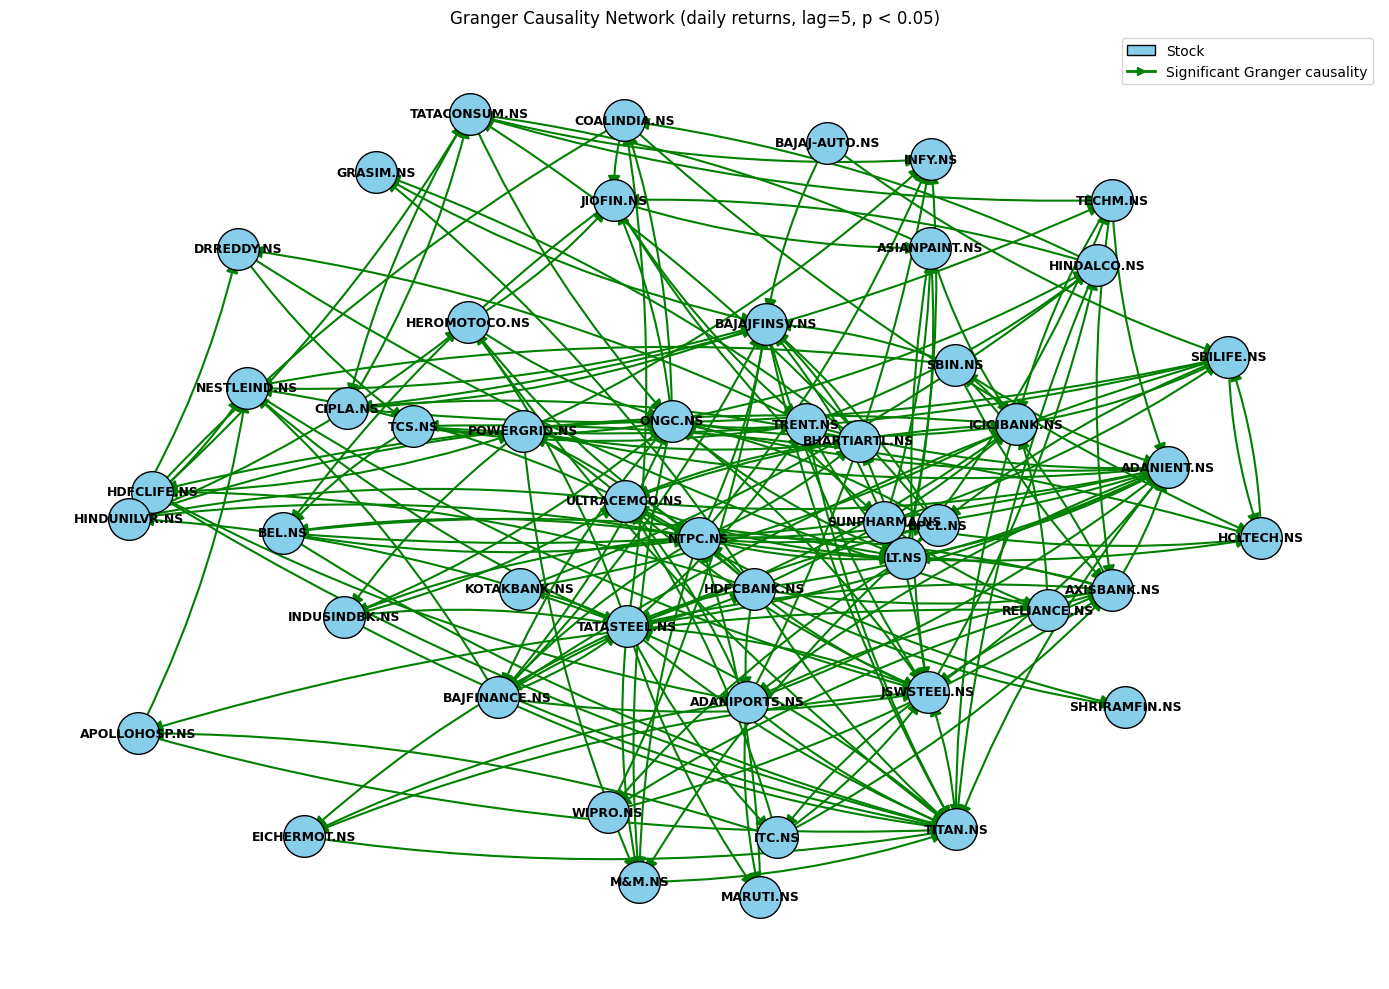

Stocks: 49 | Significant directed links: 202


In [7]:
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Create a directed graph and include every sampled stock,
# even if it has no significant connections.
G = nx.DiGraph()
G.add_nodes_from(sampled_stocks)

# Add an arrow for every significant "Yes" result.
for source in granger_matrix.index:
    for target in granger_matrix.columns:
        if source != target and granger_matrix.loc[source, target] == "Yes":
            G.add_edge(source, target)

# All nodes here are stocks, analogous to "Asset" in your example.
node_types = {ticker: "Stock" for ticker in G.nodes()}
nx.set_node_attributes(G, node_types, "type")

plt.figure(figsize=(14, 10))

pos = nx.spring_layout(G, seed=42, k=1.2)

nx.draw_networkx_nodes(
    G, pos,
    node_size=900,
    node_color="skyblue",
    edgecolors="black",
)
nx.draw_networkx_labels(
    G, pos,
    font_size=9,
    font_weight="bold",
)
nx.draw_networkx_edges(
    G, pos,
    edge_color="green",
    arrows=True,
    arrowsize=18,
    width=1.5,
    connectionstyle="arc3,rad=0.08",
)

stock_patch = Patch(
    facecolor="skyblue",
    edgecolor="black",
    label="Stock",
)
causality_line = Line2D(
    [0], [0],
    color="green",
    linewidth=2,
    marker=">",
    label="Significant Granger causality",
)
plt.legend(handles=[stock_patch, causality_line], loc="upper right")

plt.title(
    f"Granger Causality Network "
    f"(daily returns, lag={MAX_LAG}, p < {SIGNIFICANCE_LEVEL})"
)
plt.axis("off")
plt.tight_layout()
plt.show()

print(f"Stocks: {G.number_of_nodes()} | Significant directed links: {G.number_of_edges()}")